Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("RetailPulse - Data Exploration Started")

RetailPulse - Data Exploration Started


In [2]:
DATA_PATH = "../data/raw/online_retail_ii.xlsx"

df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


Inspect the dataset

In [3]:
print("Shape:", df.shape)

display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Shape: (525461, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom



Column Names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data Types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


Dataset overview

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 38.8+ MB


Statistical summary

In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,525461.00,28816.00,537434.00,675.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,525461,4632,85123A,3516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,522533,4681,WHITE HANGING HEART T-LIGHT HOLDER,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,525461.00,NaN,NaN,NaN,10.34,-9600.00,1.00,3.00,10.00,19152.00,107.42
InvoiceDate,525461,NaN,NaN,NaN,2010-06-28 11:37:36.845018,2009-12-01 07:45:00,2010-03-21 12:20:00,2010-07-06 09:51:00,2010-10-15 12:45:00,2010-12-09 20:01:00,NaN
Price,525461.00,NaN,NaN,NaN,4.69,-53594.36,1.25,2.10,4.21,25111.09,146.13
Customer ID,417534.00,NaN,NaN,NaN,15360.65,12346.00,13983.00,15311.00,16799.00,18287.00,1680.81
Country,525461,40,United Kingdom,485852,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values

In [6]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing.sort_values("Missing Percentage", ascending=False))

,Missing Count,Missing Percentage
Customer ID,107927,20.54
Description,2928,0.56
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


Duplicate records

In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

print("Unique invoices:", df["Invoice"].nunique())

print("Unique customers:", df["Customer ID"].nunique())

print("Unique products:", df["StockCode"].nunique())

Exact duplicate rows: 6865
Unique invoices: 28816
Unique customers: 4383
Unique products: 4632


Understand cancellations

In [8]:
df["Invoice"] = df["Invoice"].astype(str)

cancelled = df[df["Invoice"].str.startswith("C")]

print("Cancelled invoice rows:", len(cancelled))
print("Percentage cancelled:", round(len(cancelled) / len(df) * 100, 2), "%")

print("\nCancelled invoice examples:")
display(cancelled.head())

Cancelled invoice rows: 10206
Percentage cancelled: 1.94 %

Cancelled invoice examples:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.00,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.00,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.00,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.00,Australia


Investigate quantity and price

In [9]:
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())

print("Negative prices:", (df["Price"] < 0).sum())
print("Zero prices:", (df["Price"] == 0).sum())

print("\nQuantity distribution:")
display(df["Quantity"].describe())

print("\nPrice distribution:")
display(df["Price"].describe())

Negative quantities: 12326
Zero quantities: 0
Negative prices: 3
Zero prices: 3687

Quantity distribution:


count   525461.00
mean        10.34
std        107.42
min      -9600.00
25%          1.00
50%          3.00
75%         10.00
max      19152.00
Name: Quantity, dtype: float64


Price distribution:


count   525461.00
mean         4.69
std        146.13
min     -53594.36
25%          1.25
50%          2.10
75%          4.21
max      25111.09
Name: Price, dtype: float64

Date coverage

In [10]:
print("Earliest transaction:", df["InvoiceDate"].min())
print("Latest transaction:", df["InvoiceDate"].max())

print("\nTransactions by year:")
display(df["InvoiceDate"].dt.year.value_counts().sort_index())

print("\nTransactions by month:")
display(df.groupby(df["InvoiceDate"].dt.to_period("M")).size())

Earliest transaction: 2009-12-01 07:45:00
Latest transaction: 2010-12-09 20:01:00

Transactions by year:


InvoiceDate
2009     45228
2010    480233
Name: count, dtype: int64


Transactions by month:


InvoiceDate
2009-12    45228
2010-01    31555
2010-02    29388
2010-03    41511
2010-04    34057
2010-05    35323
2010-06    39983
2010-07    33383
2010-08    33306
2010-09    42091
2010-10    59098
2010-11    78015
2010-12    22523
Freq: M, dtype: int64

Customer and country distribution

In [11]:
print("Top 10 countries:")
display(df["Country"].value_counts().head(10))

print("\nTop 10 customers by transaction rows:")
display(df["Customer ID"].value_counts().head(10))

print("\nTop 10 products:")
display(df["Description"].value_counts().head(10))

Top 10 countries:


Country
United Kingdom     485852
EIRE                 9670
Germany              8129
France               5772
Netherlands          2769
Spain                1278
Switzerland          1187
Portugal             1101
Belgium              1054
Channel Islands       906
Name: count, dtype: int64


Top 10 customers by transaction rows:


Customer ID
14911.00    5710
17841.00    5114
14606.00    3927
14156.00    2710
12748.00    2665
17850.00    2515
16549.00    2274
15311.00    2226
14527.00    1826
14646.00    1805
Name: count, dtype: int64


Top 10 products:


Description
WHITE HANGING HEART T-LIGHT HOLDER    3549
REGENCY CAKESTAND 3 TIER              2212
STRAWBERRY CERAMIC TRINKET BOX        1843
PACK OF 72 RETRO SPOT CAKE CASES      1466
ASSORTED COLOUR BIRD ORNAMENT         1457
60 TEATIME FAIRY CAKE CASES           1400
HOME BUILDING BLOCK WORD              1386
JUMBO BAG RED RETROSPOT               1310
LUNCH BAG RED SPOTTY                  1274
REX CASH+CARRY JUMBO SHOPPER          1232
Name: count, dtype: int64

Initial visualizations

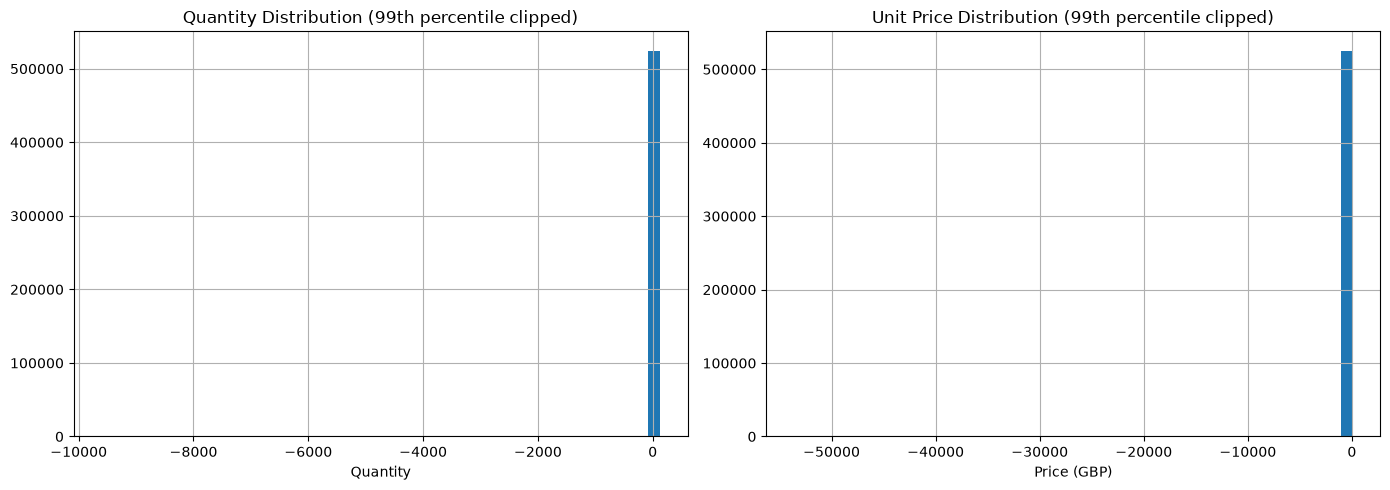

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Quantity"].clip(upper=df["Quantity"].quantile(0.99)).hist(
    bins=50, ax=axes[0]
)
axes[0].set_title("Quantity Distribution (99th percentile clipped)")
axes[0].set_xlabel("Quantity")

df["Price"].clip(upper=df["Price"].quantile(0.99)).hist(
    bins=50, ax=axes[1]
)
axes[1].set_title("Unit Price Distribution (99th percentile clipped)")
axes[1].set_xlabel("Price (GBP)")

plt.tight_layout()
plt.show()

Cancellation and returns analysis

In [13]:
# Create temporary flags; do not modify or remove original records
df["IsCancellation"] = df["Invoice"].str.startswith("C")
df["IsNegativeQuantity"] = df["Quantity"] < 0

print("Cancellation and quantity analysis:\n")

print(pd.crosstab(
    df["IsCancellation"],
    df["IsNegativeQuantity"],
    margins=True
))

print("\nCancellation rows with positive quantities:")
print(((df["IsCancellation"]) & (~df["IsNegativeQuantity"])).sum())

print("\nNegative quantity rows without cancellation invoice:")
print(((~df["IsCancellation"]) & (df["IsNegativeQuantity"])).sum())

Cancellation and quantity analysis:

IsNegativeQuantity   False   True     All
IsCancellation                           
False               513134   2121  515255
True                     1  10205   10206
All                 513135  12326  525461

Cancellation rows with positive quantities:
1

Negative quantity rows without cancellation invoice:
2121


Inspect zero-price transactions

In [14]:
zero_price = df[df["Price"] == 0]

print("Zero-price records:", len(zero_price))

display(
    zero_price[
        ["Invoice", "StockCode", "Description",
         "Quantity", "InvoiceDate", "Customer ID", "Country"]
    ].head(20)
)

print("\nMost common zero-price products:")
display(zero_price["Description"].value_counts().head(10))

Zero-price records: 3687


,Invoice,StockCode,Description,Quantity,InvoiceDate,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,NaN,United Kingdom



Most common zero-price products:


Description
?                               45
damages                         39
damaged                         38
missing                         24
OWL DOORSTOP                     8
checked                          8
POLYESTER FILLER PAD 45x45cm     7
PICNIC BASKET WICKER LARGE       7
FLAG OF ST GEORGE CAR FLAG       6
dotcom                           6
Name: count, dtype: int64

Inspect negative-price transactions

In [15]:
negative_price = df[df["Price"] < 0]

display(negative_price)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,IsNegativeQuantity
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,False,False
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,False,False
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,False,False


Inspect extreme transactions

In [16]:
print("Highest quantities:")
display(df.nlargest(10, "Quantity"))

print("\nLowest quantities:")
display(df.nsmallest(10, "Quantity"))

print("\nHighest prices:")
display(df.nlargest(10, "Price"))

print("\nLowest prices:")
display(df.nsmallest(10, "Price"))

Highest quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,IsNegativeQuantity
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.00,Denmark,False,False
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.00,Denmark,False,False
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.00,Denmark,False,False
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.00,Denmark,False,False
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.00,Denmark,False,False
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,0.00,NaN,United Kingdom,False,False
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.00,United Kingdom,False,False
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,2010-03-23 15:36:00,0.25,17940.00,United Kingdom,False,False
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.00,United Kingdom,False,False
135030,502269,21981,PACK OF 12 WOODLAND TISSUES,10000,2010-03-23 15:36:00,0.25,17940.00,United Kingdom,False,False



Lowest quantities:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,IsNegativeQuantity
303996,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.00,NaN,United Kingdom,False,True
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,0.03,15838.00,United Kingdom,True,True
156488,504311,22197,NaN,-9200,2010-04-12 14:39:00,0.00,NaN,United Kingdom,False,True
194372,507913,10120,Zebra invcing error,-9000,2010-05-11 17:16:00,0.00,NaN,United Kingdom,False,True
428975,530348,16235,?,-9000,2010-11-02 15:48:00,0.00,NaN,United Kingdom,False,True
437008,531177,20852,Given away,-8800,2010-11-05 14:40:00,0.00,NaN,United Kingdom,False,True
359669,C524235,21088,SET/6 FRUIT SALAD PAPER CUPS,-7128,2010-09-28 11:02:00,0.08,14277.00,France,True,True
258814,514363,84016,Ebay sales by the box.,-7100,2010-07-01 18:07:00,0.00,NaN,United Kingdom,False,True
359670,C524235,21096,SET/6 FRUIT SALAD PAPER PLATES,-7008,2010-09-28 11:02:00,0.13,14277.00,France,True,True
269558,515462,20852,given away,-7000,2010-07-12 15:47:00,0.00,NaN,United Kingdom,False,True



Highest prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,IsNegativeQuantity
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.00,United Kingdom,True,True
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,False,False
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom,True,True
517953,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom,True,True
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,False,False
519294,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom,True,True
519170,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,NaN,United Kingdom,True,True
135012,C502262,M,Manual,-1,2010-03-23 15:20:00,10953.50,12918.00,United Kingdom,True,True
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.00,United Kingdom,False,False
135014,C502264,M,Manual,-1,2010-03-23 15:24:00,10953.50,12918.00,United Kingdom,True,True



Lowest prices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancellation,IsNegativeQuantity
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,False,False
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,False,False
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,False,False
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom,False,True
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom,False,True
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom,False,True
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom,False,True
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom,False,True
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.00,NaN,United Kingdom,False,False
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.00,NaN,United Kingdom,False,True


Improve our distribution visualizations

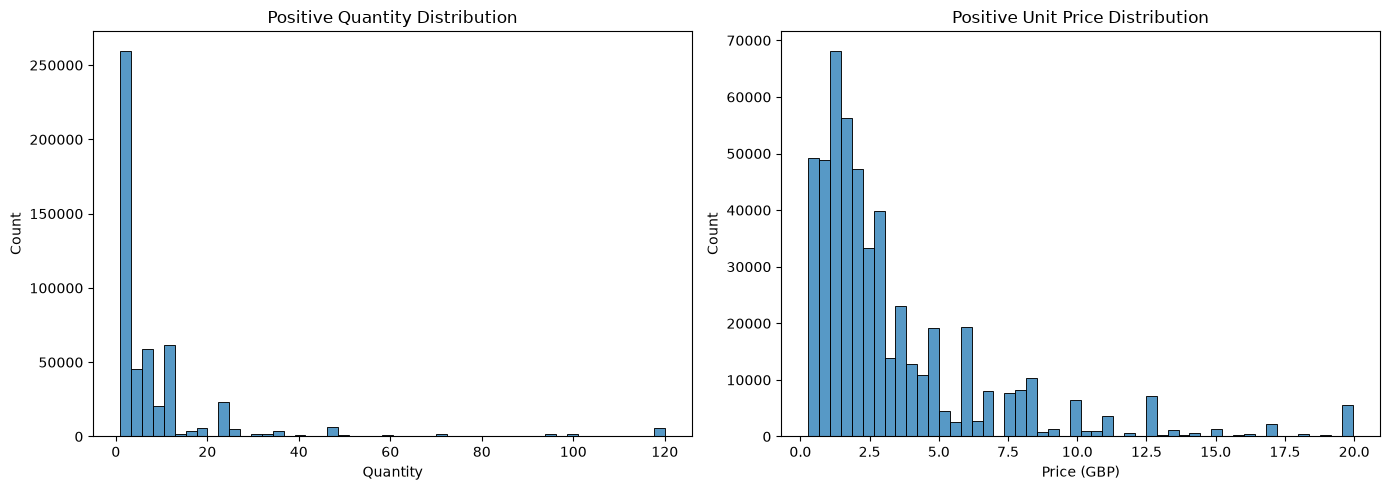

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

positive_quantity = df.loc[df["Quantity"] > 0, "Quantity"]
positive_price = df.loc[df["Price"] > 0, "Price"]

q_lower, q_upper = positive_quantity.quantile([0.01, 0.99])
p_lower, p_upper = positive_price.quantile([0.01, 0.99])

sns.histplot(
    positive_quantity.clip(q_lower, q_upper),
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Positive Quantity Distribution")
axes[0].set_xlabel("Quantity")

sns.histplot(
    positive_price.clip(p_lower, p_upper),
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Positive Unit Price Distribution")
axes[1].set_xlabel("Price (GBP)")

plt.tight_layout()
plt.show()

Check the Excel workbook sheets

In [18]:
excel_file = pd.ExcelFile(DATA_PATH)

print("Available sheets:")
print(excel_file.sheet_names)

for sheet in excel_file.sheet_names:
    temp = pd.read_excel(DATA_PATH, sheet_name=sheet)
    print(f"\nSheet: {sheet}")
    print("Shape:", temp.shape)
    print("Date range:",
          temp["InvoiceDate"].min(),
          "to",
          temp["InvoiceDate"].max())

Available sheets:
['Year 2009-2010', 'Year 2010-2011']

Sheet: Year 2009-2010
Shape: (525461, 8)
Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00

Sheet: Year 2010-2011
Shape: (541910, 8)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


Cell 19 — Load both original sheets

In [19]:
DATA_PATH = "../data/raw/online_retail_ii.xlsx"

sheet_1 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2009-2010"
)

sheet_2 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2010-2011"
)

print("Sheet 1:", sheet_1.shape)
print("Sheet 2:", sheet_2.shape)

print("\nColumn compatibility:")
print(sheet_1.columns.equals(sheet_2.columns))

Sheet 1: (525461, 8)
Sheet 2: (541910, 8)

Column compatibility:
True


Cell 20 — Compare date ranges

In [20]:
for name, data in [
    ("Sheet 1", sheet_1),
    ("Sheet 2", sheet_2)
]:
    print(f"\n{name}")
    print("Start:", data["InvoiceDate"].min())
    print("End:", data["InvoiceDate"].max())

overlap_start = max(
    sheet_1["InvoiceDate"].min(),
    sheet_2["InvoiceDate"].min()
)

overlap_end = min(
    sheet_1["InvoiceDate"].max(),
    sheet_2["InvoiceDate"].max()
)

print("\nOverlapping period:", overlap_start, "to", overlap_end)


Sheet 1
Start: 2009-12-01 07:45:00
End: 2010-12-09 20:01:00

Sheet 2
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Overlapping period: 2010-12-01 08:26:00 to 2010-12-09 20:01:00


Cell 21 — Check cross-sheet duplicates

In [21]:
# Exact matching records across the two sheets
comparison_columns = sheet_1.columns.tolist()

merged_check = sheet_1.merge(
    sheet_2[comparison_columns].drop_duplicates(),
    on=comparison_columns,
    how="inner"
)

print("Exact records appearing in both sheets:", len(merged_check))

Exact records appearing in both sheets: 22523


Cell 22 — Check invoice overlap

In [22]:
invoices_1 = set(sheet_1["Invoice"].astype(str))
invoices_2 = set(sheet_2["Invoice"].astype(str))

common_invoices = invoices_1.intersection(invoices_2)

print("Invoices in Sheet 1:", len(invoices_1))
print("Invoices in Sheet 2:", len(invoices_2))
print("Invoices appearing in both:", len(common_invoices))

Invoices in Sheet 1: 28816
Invoices in Sheet 2: 25900
Invoices appearing in both: 1088


Cell 23 — Combine the data

In [23]:
df_raw = pd.concat(
    [sheet_1, sheet_2],
    ignore_index=True
)

print("Combined shape:", df_raw.shape)

print("Date range:",
      df_raw["InvoiceDate"].min(),
      "to",
      df_raw["InvoiceDate"].max())

print("Exact duplicates:", df_raw.duplicated().sum())

Combined shape: (1067371, 8)
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Exact duplicates: 34335


Cell 24 — Preserve the source of every record

In [24]:
sheet_1 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2009-2010"
)

sheet_2 = pd.read_excel(
    DATA_PATH,
    sheet_name="Year 2010-2011"
)

sheet_1["SourceSheet"] = "2009-2010"
sheet_2["SourceSheet"] = "2010-2011"

df_raw = pd.concat(
    [sheet_1, sheet_2],
    ignore_index=True
)

print("Combined shape:", df_raw.shape)

Combined shape: (1067371, 9)


Cell 25 — Duplicate audit by sheet

In [25]:
print("Sheet 1 duplicate rows:",
      sheet_1.drop(columns="SourceSheet").duplicated().sum())

print("Sheet 2 duplicate rows:",
      sheet_2.drop(columns="SourceSheet").duplicated().sum())

print("\nCombined duplicate rows:")
print(
    df_raw.drop(columns="SourceSheet").duplicated().sum()
)

Sheet 1 duplicate rows: 6865
Sheet 2 duplicate rows: 5268

Combined duplicate rows:
34335


Cell 26 — Inspect cross-sheet duplicates

In [26]:
comparison_columns = [
    col for col in sheet_1.columns
    if col != "SourceSheet"
]

cross_duplicates = sheet_1.merge(
    sheet_2[comparison_columns].drop_duplicates(),
    on=comparison_columns,
    how="inner"
)

print("Cross-sheet matching records:",
      len(cross_duplicates))

display(cross_duplicates.head(15))

Cross-sheet matching records: 22523


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom,2009-2010
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom,2009-2010
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom,2009-2010
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom,2009-2010
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom,2009-2010
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.00,United Kingdom,2009-2010
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.00,United Kingdom,2009-2010
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.00,United Kingdom,2009-2010
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.00,United Kingdom,2009-2010
9,536368,22960,JAM MAKING SET WITH JARS,6,2010-12-01 08:34:00,4.25,13047.00,United Kingdom,2009-2010


Cell 27 — Check repeated product lines

In [27]:
duplicate_mask = df_raw.duplicated(
    subset=comparison_columns,
    keep=False
)

duplicate_records = df_raw[duplicate_mask].sort_values(
    ["Invoice", "StockCode", "InvoiceDate"]
)

display(duplicate_records.head(30))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SourceSheet
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.00,United Kingdom,2009-2010
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.00,United Kingdom,2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom,2009-2010
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom,2009-2010
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom,2009-2010
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom,2009-2010
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom,2009-2010
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom,2009-2010
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.00,United Kingdom,2009-2010
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.00,United Kingdom,2009-2010


Cell 28 — Monthly transaction trends

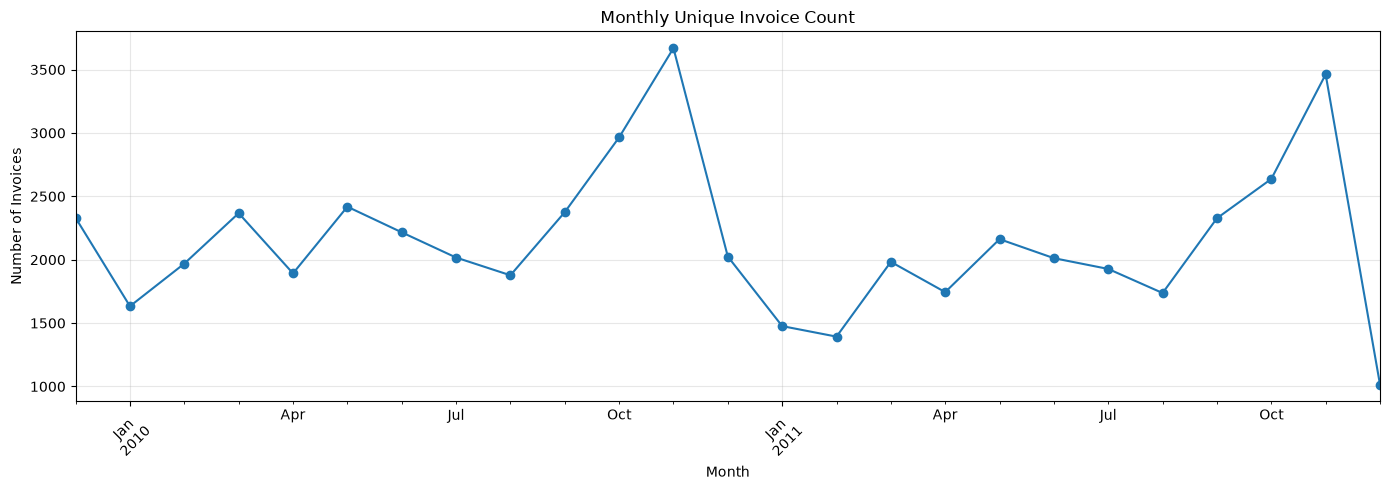

In [28]:
df_eda = df_raw.copy()

monthly_transactions = (
    df_eda.groupby(df_eda["InvoiceDate"].dt.to_period("M"))
    ["Invoice"].nunique()
)

plt.figure(figsize=(14, 5))
monthly_transactions.plot(kind="line", marker="o")

plt.title("Monthly Unique Invoice Count")
plt.xlabel("Month")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cell 29 — Monthly recorded revenue

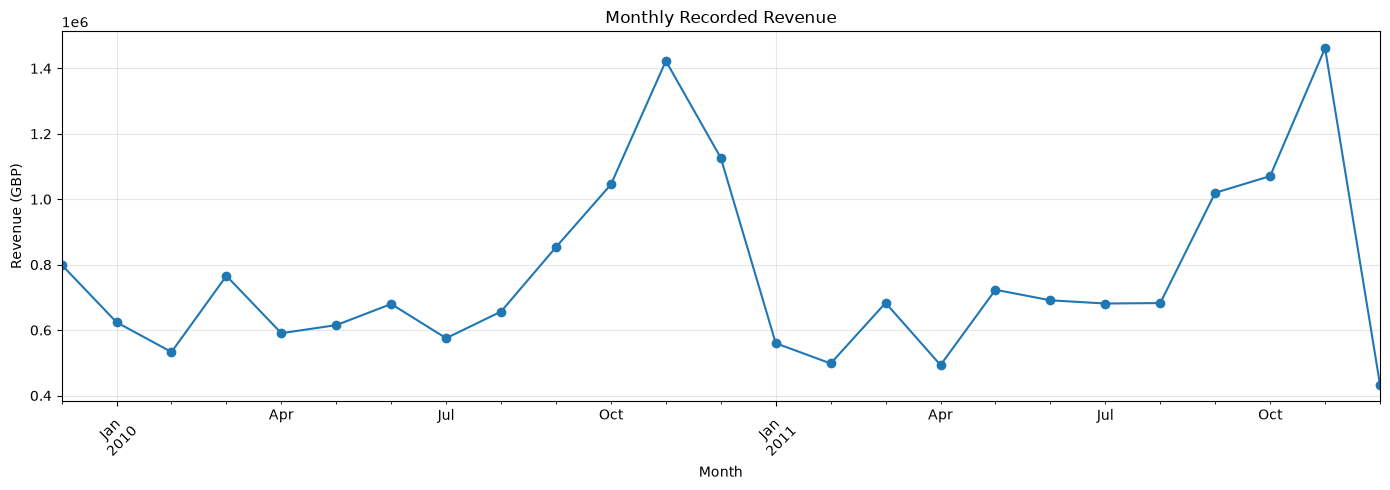

In [29]:
df_eda["Revenue"] = df_eda["Quantity"] * df_eda["Price"]

monthly_revenue = (
    df_eda.groupby(df_eda["InvoiceDate"].dt.to_period("M"))
    ["Revenue"].sum()
)

plt.figure(figsize=(14, 5))
monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Recorded Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cell 30 — Customer purchase frequency

count   5942.00
mean       7.55
std       15.97
min        1.00
25%        2.00
50%        4.00
75%        8.00
max      510.00
Name: Invoice, dtype: float64

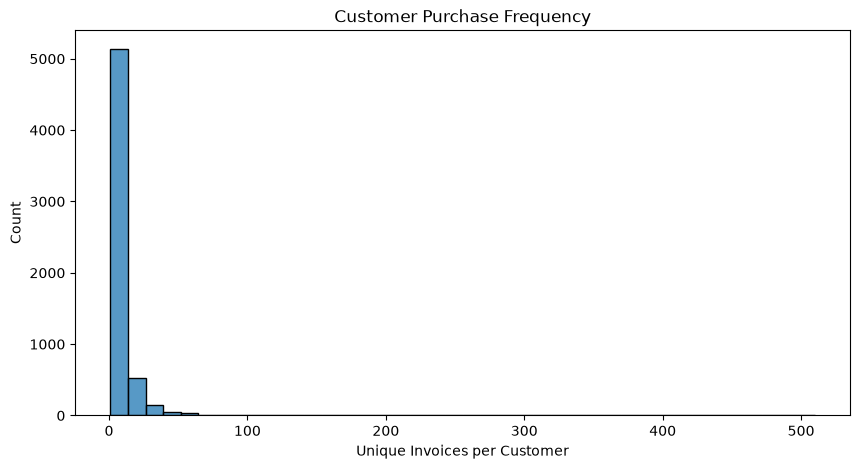

In [30]:
identified = df_eda.dropna(subset=["Customer ID"]).copy()

customer_invoices = (
    identified.groupby("Customer ID")["Invoice"]
    .nunique()
)

display(customer_invoices.describe())

plt.figure(figsize=(10, 5))
sns.histplot(customer_invoices, bins=40)

plt.title("Customer Purchase Frequency")
plt.xlabel("Unique Invoices per Customer")
plt.show()

Cell 31 — Customer spending distribution

count     5942.00
mean      2801.80
std      13973.92
min     -25111.09
25%        325.10
50%        843.97
75%       2182.01
max     598215.22
Name: Revenue, dtype: float64

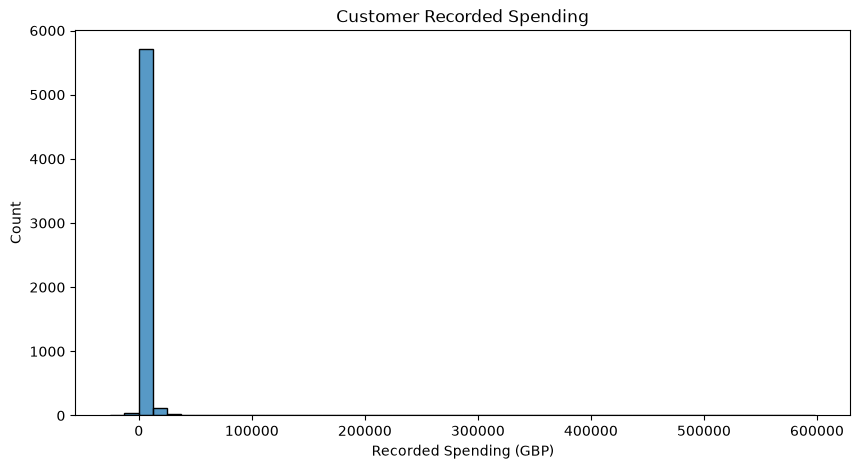

In [31]:
customer_spending = (
    identified.groupby("Customer ID")["Revenue"]
    .sum()
)

display(customer_spending.describe())

plt.figure(figsize=(10, 5))
sns.histplot(customer_spending, bins=50)

plt.title("Customer Recorded Spending")
plt.xlabel("Recorded Spending (GBP)")
plt.show()

Cell 32 — Monthly active customers

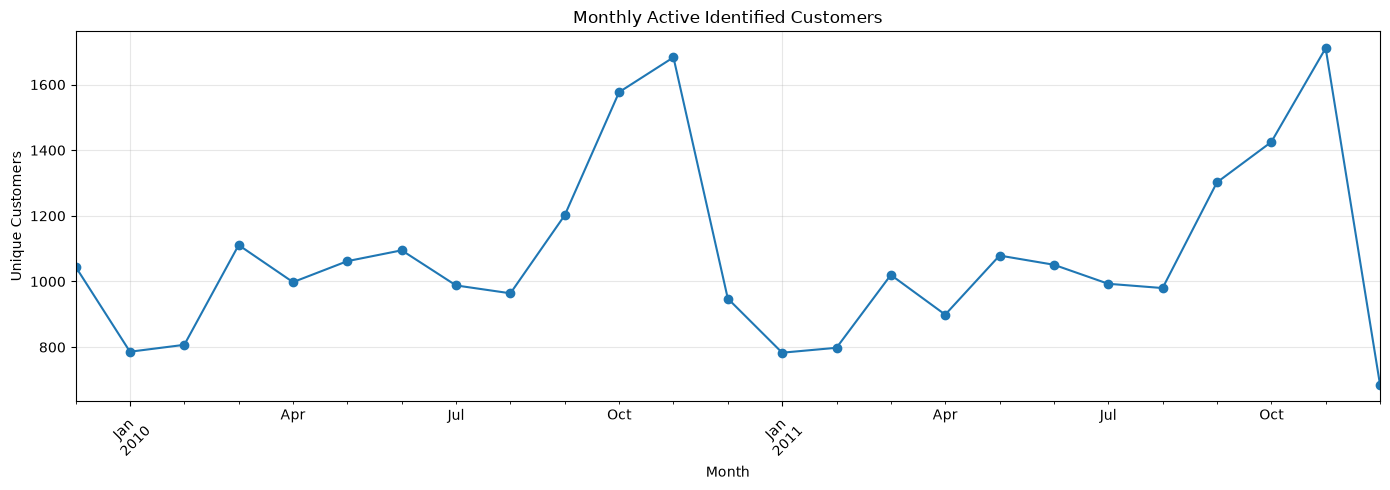

In [32]:
identified["YearMonth"] = (
    identified["InvoiceDate"].dt.to_period("M")
)

monthly_active_customers = (
    identified.groupby("YearMonth")["Customer ID"]
    .nunique()
)

plt.figure(figsize=(14, 5))
monthly_active_customers.plot(marker="o")

plt.title("Monthly Active Identified Customers")
plt.xlabel("Month")
plt.ylabel("Unique Customers")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Cell 33 — Transaction basket sizes

count   53628.00
mean       19.05
std        37.84
min         1.00
25%         1.00
50%         9.00
75%        22.00
max      1110.00
Name: StockCode, dtype: float64

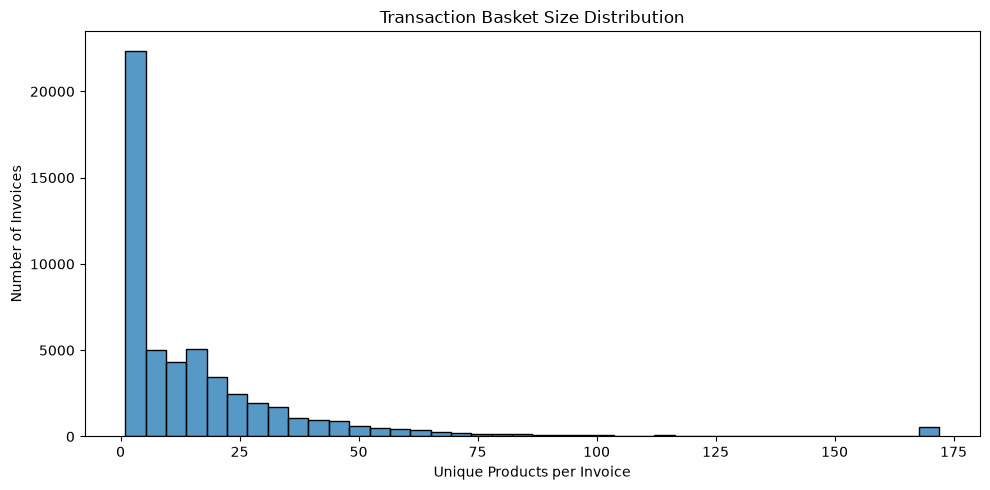

In [33]:
basket_sizes = (
    df_eda.groupby("Invoice")["StockCode"]
    .nunique()
)

display(basket_sizes.describe())

plt.figure(figsize=(10, 5))
sns.histplot(basket_sizes.clip(upper=basket_sizes.quantile(0.99)), bins=40)

plt.title("Transaction Basket Size Distribution")
plt.xlabel("Unique Products per Invoice")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.show()

Cell 34 — Most frequently purchased products

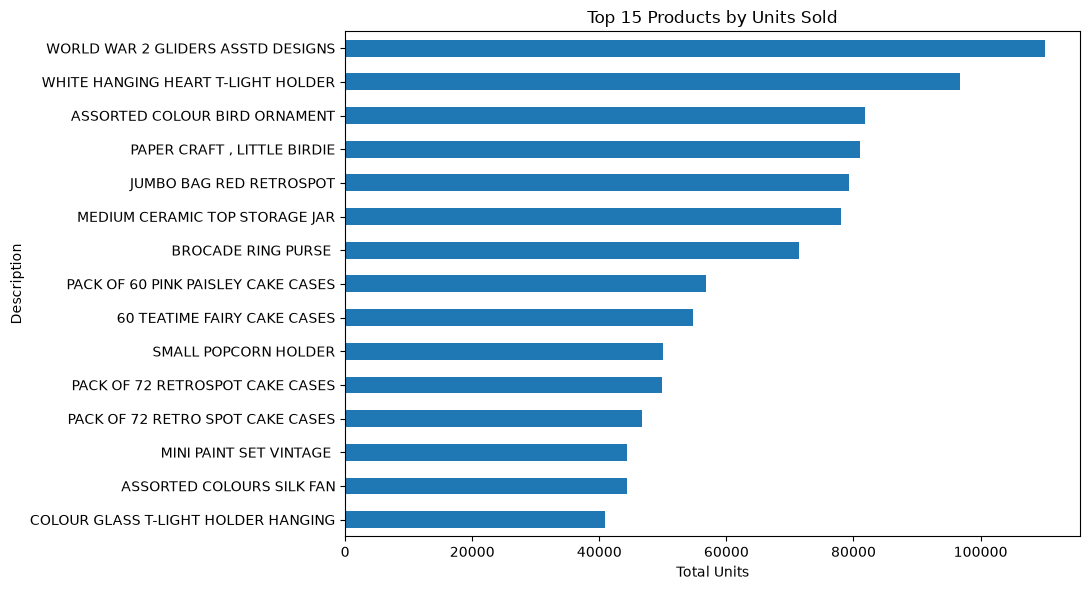

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS      110138
WHITE HANGING HEART T-LIGHT HOLDER      96683
ASSORTED COLOUR BIRD ORNAMENT           81809
PAPER CRAFT , LITTLE BIRDIE             80995
JUMBO BAG RED RETROSPOT                 79279
MEDIUM CERAMIC TOP STORAGE JAR          78033
BROCADE RING PURSE                      71430
PACK OF 60 PINK PAISLEY CAKE CASES      56794
60 TEATIME FAIRY CAKE CASES             54716
SMALL POPCORN HOLDER                    49948
PACK OF 72 RETROSPOT CAKE CASES         49805
PACK OF 72 RETRO SPOT CAKE CASES        46755
MINI PAINT SET VINTAGE                  44405
ASSORTED COLOURS SILK FAN               44365
COLOUR GLASS T-LIGHT HOLDER HANGING     40839
Name: Quantity, dtype: int64

In [34]:
purchase_view = df_eda[
    (~df_eda["Invoice"].astype(str).str.startswith("C")) &
    (df_eda["Quantity"] > 0) &
    (df_eda["Price"] > 0)
].copy()

top_products = (
    purchase_view.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(11, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 15 Products by Units Sold")
plt.xlabel("Total Units")
plt.tight_layout()
plt.show()

display(top_products)

Cell 35 — Purchasing activity by weekday

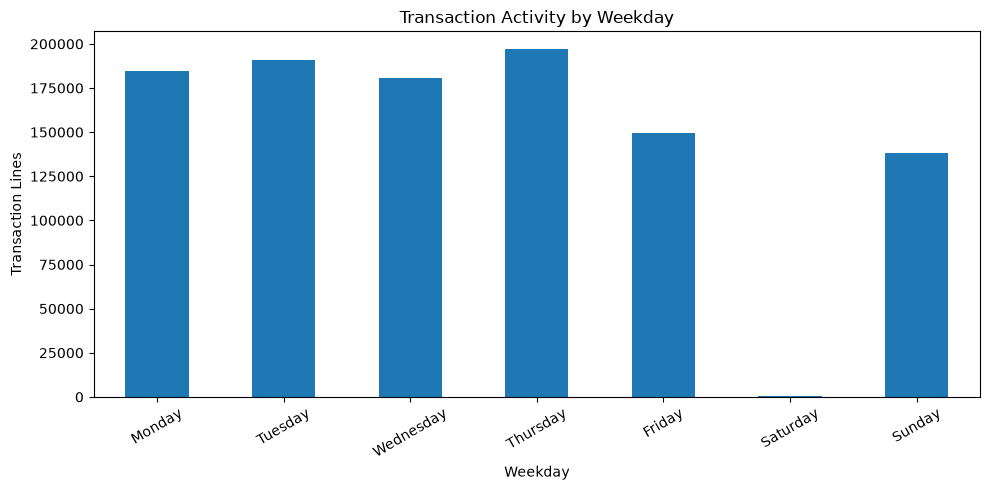

In [35]:
weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_counts = (
    purchase_view["InvoiceDate"]
    .dt.dayofweek
    .value_counts()
    .reindex(range(7), fill_value=0)
)

weekday_counts.index = weekday_names

plt.figure(figsize=(10, 5))
weekday_counts.plot(kind="bar")

plt.title("Transaction Activity by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Transaction Lines")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Cell 36 — Purchasing activity by hour

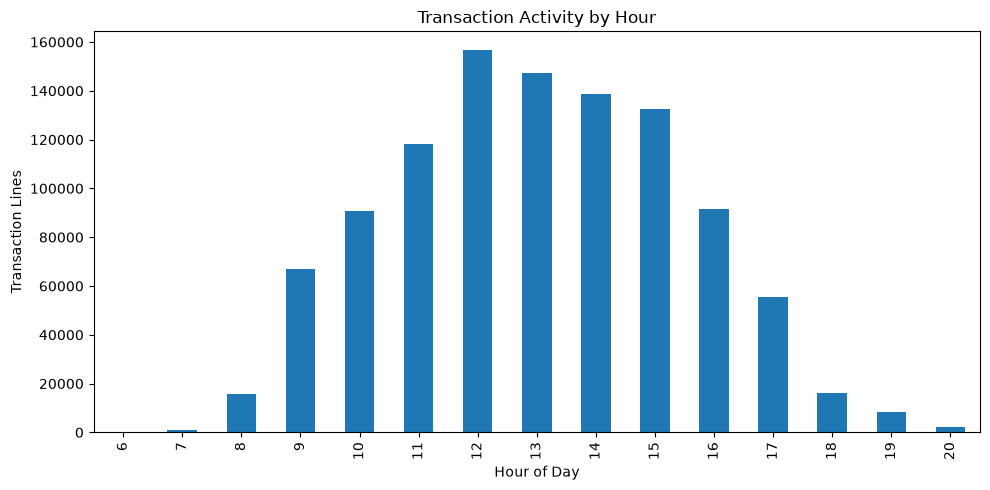

In [36]:
hourly_counts = (
    purchase_view["InvoiceDate"]
    .dt.hour
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))
hourly_counts.plot(kind="bar")

plt.title("Transaction Activity by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Transaction Lines")
plt.tight_layout()
plt.show()